# 数据集计数与分布

从已核验的全文件统计重新绘图；release 快照和父数据量保留各自来源，不混合相加。

In [1]:
import sys, json, io
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir())
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import render_datasets
audit = json.loads((root / 'documentation/assets/dataset_audit.json').read_text())
for row in audit['datasets']:
    assert sum(row['modality_records'].values()) == row['records']
    print(row['id'], row['records'], row['unique_canonical_isomeric_smiles'], row['modality_records'])


nmrspec_test 10000 10000 {'H+C': 10000}
patent_test_10k 10000 10000 {'H only': 8707, 'H+C': 1241, 'C only': 52}
nmrexp_exp_10k 9183 9183 {'H+C': 3292, 'H only': 5690, 'C only': 201}
nmrgym_test 10000 10000 {'H+C': 10000}
openspec_test 20390 16728 {'H+C': 20388, 'C only': 2}


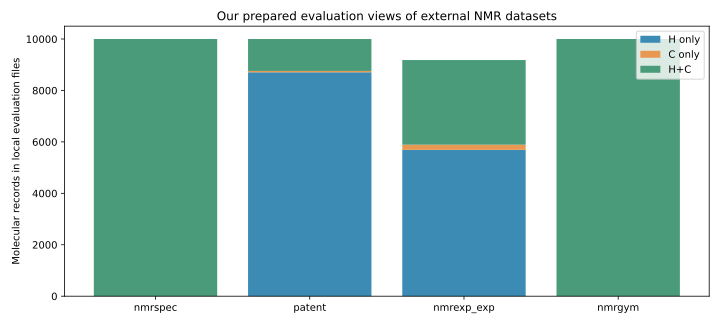

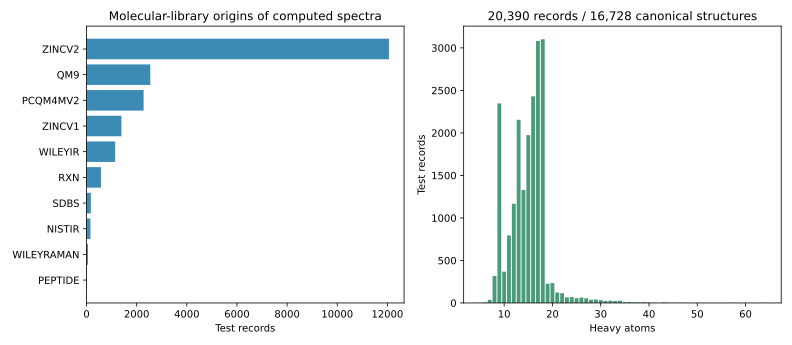

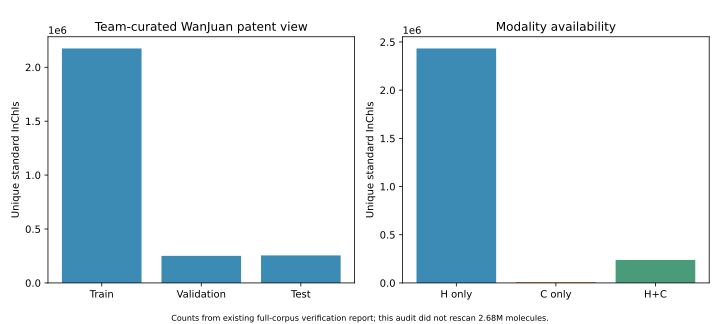

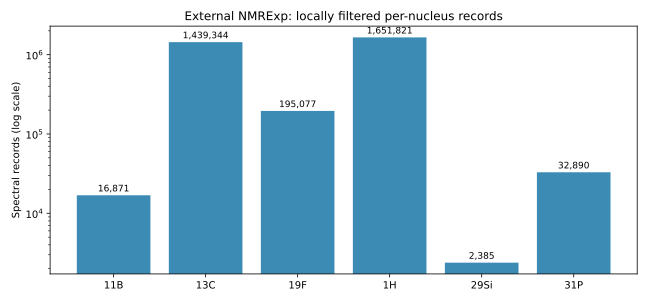

In [2]:
import matplotlib.pyplot as plt
for name, figure in render_datasets(save=False).items():
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)
